Redoing the original e-Holm and e-DAG simulations

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# Functions

In [ ]:
def e_holm(evals):
  if len(evals) == 0:
    return []

  pairs = sorted(enumerate(evals), key=lambda t: t[1], reverse = True)
  orig_idx = [i for i, _ in pairs]
  e_sorted = [x for _, x in pairs]
  n = len(e_sorted)

  e_adjusted = np.zeros(n)
  e_adjusted[n-1] = e_sorted[n-1]

  k = 1
  E_k = e_sorted[n-k]
  e_adj = float('inf')
  for r in range(1, n):
    i = n - 1 - r
    e = e_sorted[i]
    e_adj = e / (k+1) + E_k * k / (k+1)
    while(e_adj > e_sorted[n - k - 1]):
      E_k = E_k * k / (k+1) + e_sorted[n - k - 1] / (k+1)
      k = k + 1
      e_adj = e / (k+1) + E_k * k / (k+1)
      if k == n:
        break
    e_adjusted[i] = e_adj

  adjusted = np.zeros(n)
  for sorted_pos, i in enumerate(orig_idx):
    adjusted[i] = e_adjusted[sorted_pos]
  return adjusted

In [ ]:
def p_holm(pvals):
  if len(pvals) == 0:
    return []

  pairs = sorted(enumerate(pvals), key=lambda t: t[1])
  orig_idx = [i for i, _ in pairs]
  p_sorted = [x for _, x in pairs]
  n = len(p_sorted)

  p_adjusted = np.zeros(n)
  p_adj = p_sorted[0] * n
  p_adjusted[0] = p_adj

  for i in range(1,n):
    p_i = p_sorted[i] * (n - i)
    if p_i > p_adj:
      p_adj = p_i
    p_adjusted[i] = min(p_adj, 1)

  adjusted = np.zeros(n)
  for sorted_pos, i in enumerate(orig_idx):
    adjusted[i] = p_adjusted[sorted_pos]
  return adjusted


In [ ]:
from itertools import combinations

# ordering: 0=b1, 1=b2, 2=b3, 3=b12, 4=b13, 5=b23, 6=b123

children = {
    0: [(3, 0.5), (4, 0.5)],
    1: [(3, 0.5), (5, 0.5)],
    2: [(4, 0.5), (5, 0.5)],
    3: [(6, 1.0)],
    4: [(6, 1.0)],
    5: [(6, 1.0)],
    6: []
}

def _weights_for_subset(I, b):
    I = set(I)
    w = [0.0] * 7

    def push(j, mass):
        if j in I:
            w[j] += mass
        else:
            for k, q in children[j]:
                push(k, mass * q)

    for j, bj in enumerate(b):
        if bj > 0:
            push(j, bj)
    return w

def adj_eval_6(evals, budget="equal"):
    if budget == "equal":
        b = [1/7] * 7
    elif budget == "primary":
        b = [1/3, 1/3, 1/3, 0, 0, 0, 0]
    else:
        raise ValueError("budget must be 'equal' or 'primary'")

    out = float("inf")
    nodes = range(6)  # optional ancestors besides node 6
    for r in range(7):
        for S in combinations(nodes, r):
            I = set(S) | {6}
            w = _weights_for_subset(I, b)
            out = min(out, sum(w[j] * evals[j] for j in range(7)))
    return out

def adj_pval_6(pvals, budget="equal"):
    if budget == "equal":
        b = [1/7] * 7
    elif budget == "primary":
        b = [1/3, 1/3, 1/3, 0, 0, 0, 0]
    else:
        raise ValueError("budget must be 'equal' or 'primary'")

    out = 0.0
    nodes = range(6)
    for r in range(7):
        for S in combinations(nodes, r):
            I = set(S) | {6}
            w = _weights_for_subset(I, b)
            local = min(pvals[j] / w[j] for j in I if w[j] > 0)
            out = max(out, local)
    return out

In [ ]:
def e_dag(evals, budget = 'primary', EB_divide = 7):
  d = EB_divide
  # ignore three-way interaction
  adj_evals = np.zeros(7)
  if budget == 'primary':
    for i in range(3):
      adj_evals[i] = evals[i] / 3
    adj_evals[3] = min((evals[0] + evals[1]) / 3, (evals[0] + evals[3] / 2) / 3, (evals[1] + evals[3] / 2) / 3, evals[3] / 3)
    adj_evals[4] = min((evals[0] + evals[2]) / 3, (evals[0] + evals[4] / 2) / 3, (evals[2] + evals[4] / 2) / 3, evals[4] / 3)
    adj_evals[5] = min((evals[1] + evals[2]) / 3, (evals[1] + evals[5] / 2) / 3, (evals[2] + evals[5] / 2) / 3, evals[5] / 3)
    adj_evals[6] = adj_eval_6(evals, budget = budget)
  else:
    for i in range(3):
      adj_evals[i] = evals[i] / d
    adj_evals[3] = min((evals[0] + evals[1] + evals[3]) / d, (evals[0] + 1.5 * evals[3]) / d,
     (evals[1] + 1.5 * evals[3]) / d, 2 * evals[3] / d)
    adj_evals[4] = min((evals[0] + evals[2] + evals[4]) / d, (evals[0] + 1.5 * evals[4]) / d,
     (evals[2] + 1.5 * evals[4]) / d, 2 * evals[4] / d)
    adj_evals[3] = min((evals[1] + evals[2] + evals[5]) / d, (evals[1] + 1.5 * evals[5]) / d,
     (evals[2] + 1.5 * evals[5]) / d, 2 * evals[5] / d)
    adj_evals[6] = adj_eval_6(evals, budget = budget)
  return adj_evals

In [ ]:
def p_dag(pvals, budget = 'primary', EB_divide = 7):
  d = EB_divide
  adj_pvals = np.zeros(7)
  if budget == 'primary':
    for i in range(3):
      adj_pvals[i] = pvals[i] * 3
    adj_pvals[3] = max(min(pvals[0], pvals[1]) * 3, 3 * pvals[3], min(pvals[0], 2 * pvals[3]) * 3, min(pvals[1], 2 * pvals[3]) * 3)
    adj_pvals[4] = max(min(pvals[0], pvals[2]) * 3, 3 * pvals[4], min(pvals[0], 2 * pvals[4]) * 3, min(pvals[2], 2 * pvals[4]) * 3)
    adj_pvals[5] = max(min(pvals[1], pvals[2]) * 3, 3 * pvals[5], min(pvals[1], 2 * pvals[5]) * 3, min(pvals[2], 2 * pvals[5]) * 3)
    adj_pvals[6] = adj_pval_6(pvals, budget = budget)
  else:
    for i in range(3):
      adj_pvals[i] = pvals[i] * d
    adj_pvals[3] = max(min(pvals[0], pvals[1], pvals[3]) * d, d * pvals[3] / 2,
                       min(pvals[0], pvals[3] / 1.5) * d, min(pvals[1], pvals[3] / 1.5) * d)
    adj_pvals[4] = max(min(pvals[0], pvals[2], pvals[4]) * d, d * pvals[4] / 2,
                       min(pvals[0], pvals[4] / 1.5) * d, min(pvals[2], pvals[4] / 1.5) * d)
    adj_pvals[5] = max(min(pvals[1], pvals[2], pvals[5]) * d, d * pvals[5] / 2,
                       min(pvals[1], pvals[5] / 1.5) * d, min(pvals[2], pvals[5] / 1.5) * d)
    adj_pvals[6] = adj_pval_6(pvals, budget = budget)
  return adj_pvals

# e-Holm

In [ ]:
def run_processes(n = 20, n_1 = 5, mu_1 = 0.5, alpha = 0.05, max_steps = 100, seed = 0):
  T_p = float('inf')
  T_ep = float('inf')
  T_e = float('inf')

  n_0 = n - n_1

  e_processes = np.ones(n)
  maxima = np.ones(n)

  FWER_powers = np.zeros((5, 2))

  np.random.seed(seed)
  for t in range(max_steps):
    alts = np.random.normal(mu_1, 1, size = n_1)
    nulls = np.random.normal(0, 1, size = n_0)
    e_processes[:n_1] = e_processes[:n_1] * np.exp(mu_1 * alts - 0.5 * mu_1 ** 2)
    e_processes[n_1:] = e_processes[n_1:] * np.exp(mu_1 * nulls - 0.5 * mu_1 ** 2)
    maxima = np.maximum(maxima, e_processes)

    if T_p == float('inf'):
      best_p = np.min(p_holm(1/maxima))
      if best_p <= alpha:
        T_p = t+1

    if T_ep == float('inf'):
      best_ep = np.min(p_holm(1/e_processes))
      if best_ep <= alpha:
        T_ep = t+1

    if T_e == float('inf'):
      best_e = np.max(e_holm(e_processes))
      if best_e >= 1/alpha:
        T_e = t+1

  Ts = np.array([T_p, T_e, T_ep])


  adj_pvals = p_holm(1/maxima)
  FWER_powers[0,0] = np.any(adj_pvals[n_1:] <= alpha)
  FWER_powers[0,1] = np.mean(adj_pvals[:n_1] <= alpha)

  adj_evals = e_holm(e_processes)
  FWER_powers[1,0] = np.any(adj_evals[n_1:] >= 1/alpha)
  FWER_powers[1,1] = np.mean(adj_evals[:n_1] >= 1/alpha)

  adj_epvals = p_holm(1/e_processes)
  FWER_powers[2,0] = np.any(adj_epvals[n_1:] <= alpha)
  FWER_powers[2,1] = np.mean(adj_epvals[:n_1] <= alpha)

  alpha_prime = 0.03763148569601143
  adj_emvals = e_holm(maxima)
  FWER_powers[3,0] = np.any(adj_emvals[n_1:] >= 1/alpha)
  FWER_powers[3,1] = np.mean(adj_emvals[:n_1] >= 1/alpha)
  FWER_powers[4,0] = np.any(adj_emvals[n_1:] >= 1/alpha_prime)
  FWER_powers[4,1] = np.mean(adj_emvals[:n_1] >= 1/alpha_prime)

  return Ts, FWER_powers

In [ ]:
run_processes(max_steps = 100)

[5.95312619e+04 3.26351763e+03 1.51720971e+06 3.54373204e+06
 2.62441074e+02 4.64032644e-07 1.57212919e-06 7.57971913e-04
 8.68055996e-05 1.41868921e-02 1.26085092e-10 2.34826188e-07
 1.04313369e-05 1.01864196e-08 2.59528793e-04 3.23235936e-03
 1.96601085e-06 2.24806722e-10 1.69287403e-06 1.88847201e-07]


(array([46, 46, 46]),
 array([[0. , 1. ],
        [0. , 0.8],
        [0. , 0.8]]))

In [ ]:
mu_1s = np.array([0.5, 1, 1.5, 2])
num_mus = len(mu_1s)
num_iter = 1000

Ts_array = np.zeros((num_iter, num_mus, 3))
FWER_powers_array = np.zeros((num_iter, num_mus, 3, 2))
for i in tqdm(range(num_iter)):
  for j in range(num_mus):
    Ts, FWER_powers = run_processes(mu_1 = mu_1s[j], seed = i, max_steps = 20)
    Ts_array[i, j, :] = Ts
    FWER_powers_array[i, j, :, :] = FWER_powers


100%|██████████| 1000/1000 [00:07<00:00, 141.65it/s]


In [ ]:
Ts_holm = Ts_array.mean(axis = 0)
Ts_holm

array([[24.94 , 24.231, 24.94 ],
       [ 6.891,  6.692,  6.891],
       [ 3.362,  3.277,  3.362],
       [ 2.148,  2.099,  2.148]])

In [ ]:
rates_holm = FWER_powers_array.mean(axis = 0)
rates_holm

array([[[0.    , 0.074 ],
        [0.    , 0.0696],
        [0.    , 0.0618]],

       [[0.023 , 0.8778],
        [0.003 , 0.836 ],
        [0.003 , 0.834 ]],

       [[0.025 , 0.9974],
        [0.    , 0.9958],
        [0.    , 0.9958]],

       [[0.014 , 0.9998],
        [0.    , 0.9998],
        [0.    , 0.9998]]])

In [ ]:
rates_holm.shape

(4, 3, 2)

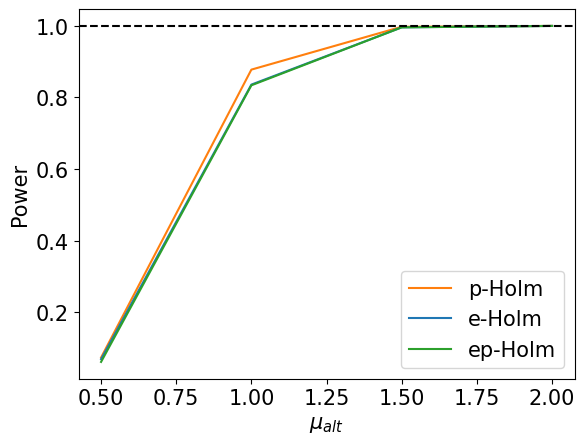

In [ ]:
plt.rcParams.update({'font.size': 15})
colors = ['C1', 'C0', 'C2']
methods = ['p-Holm','e-Holm','ep-Holm']
for i in range(3):
  plt.plot(mu_1s, rates_holm[:,i,1], label = methods[i], color = colors[i])

plt.xlabel(r'$\mu_{alt}$')
plt.ylabel('Power')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

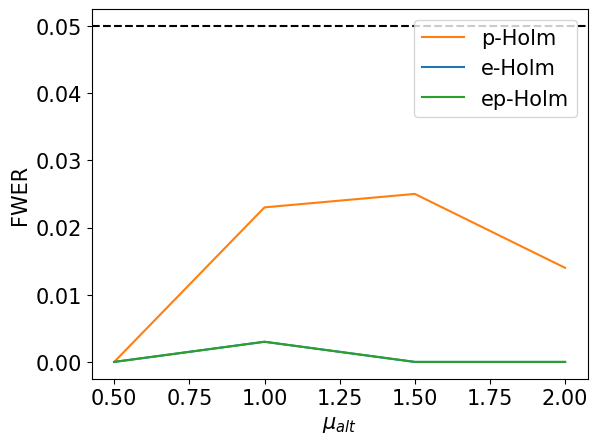

In [ ]:
plt.rcParams.update({'font.size': 15})
colors = ['C1', 'C0', 'C2']
methods = ['p-Holm','e-Holm','ep-Holm']
for i in range(3):
  plt.plot(mu_1s, rates_holm[:,i,0], label = methods[i], color = colors[i])

plt.xlabel(r'$\mu_{alt}$')
plt.ylabel('FWER')
plt.axhline(0.05, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

In [ ]:
np.minimum(Ts_array[:,:,1], 100)/np.minimum(Ts_array[:,:,0], 100)

In [ ]:
np.any(np.minimum(Ts_array[:,:,0], 100) == 0)

np.True_

In [ ]:
ratios = np.zeros(4)
for j in range(4):
  Ts_e = Ts_array[:,j,1][Ts_array[:,j,1] < Ts_array[:,j,0]]
  Ts_p = Ts_array[:,j,0][Ts_array[:,j,1] < Ts_array[:,j,0]]
  ratios[j] = np.mean(Ts_e / Ts_p)

/tmp/ipykernel_1715/854826314.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


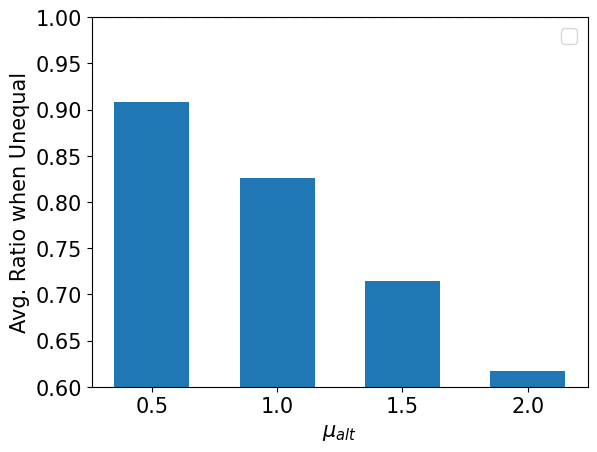

In [ ]:
plt.rcParams.update({'font.size': 15})
plt.bar(x=mu_1s, height = ratios, width = 0.3, align = 'center', color = 'C0')

plt.ylim(0.6,1)
plt.xlabel(r'$\mu_{alt}$')
plt.ylabel('Avg. Ratio when Unequal')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

/tmp/ipykernel_1715/2090596440.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


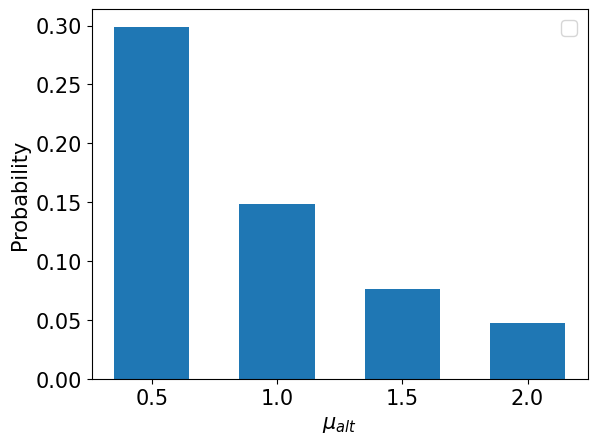

In [ ]:
plt.rcParams.update({'font.size': 15})
plt.bar(x=mu_1s, height = np.mean(Ts_array[:,:,1] < Ts_array[:,:,0], axis = 0), width = 0.3, align = 'center', color = 'C0')

plt.xlabel(r'$\mu_{alt}$')
plt.ylabel('Probability')
plt.legend()
plt.show()

# e-DAG

In [ ]:
betas = np.array([0.5, 0, 0.5, 0, 0.5, 0, 0])
vars = np.array([2, 2, 2, 4, 4, 4, 8])

data_means = np.array([0, 0.5, 0, 0.5, 0.5, 1.5, 0.5, 1.5])

In [ ]:
beta_contrasts = np.array([
    # beta_1 = mu100 - mu000
    [-1,  0,  0,  0,  1,  0,  0,  0],

    # beta_2 = mu010 - mu000
    [-1,  0,  1,  0,  0,  0,  0,  0],

    # beta_3 = mu001 - mu000
    [-1,  1,  0,  0,  0,  0,  0,  0],

    # beta_12 = mu110 - mu100 - mu010 + mu000
    [ 1,  0, -1,  0, -1,  0,  1,  0],

    # beta_13 = mu101 - mu100 - mu001 + mu000
    [ 1, -1,  0,  0, -1,  1,  0,  0],

    # beta_23 = mu011 - mu010 - mu001 + mu000
    [ 1, -1, -1,  1,  0,  0,  0,  0],

    # beta_123 = mu111 - mu110 - mu101 - mu011 + mu100 + mu010 + mu001 - mu000
    [-1,  1,  1, -1,  1, -1, -1,  1],
], dtype=int)

def eval_factorial(data, mu_alt, vars = vars):
  contrasts = beta_contrasts @ data
  #print(mu_alt)
  #print(contrasts)
  #print(vars)
  return np.exp(mu_alt * contrasts / vars - 0.5 * mu_alt ** 2 / vars)

In [ ]:
eval_factorial(np.zeros(8), data_means[1:])

[0.5 0.  0.5 0.5 1.5 0.5 1.5]
[0. 0. 0. 0. 0. 0. 0.]
[2 2 2 4 4 4 8]


array([0.93941306, 1.        , 0.93941306, 0.96923323, 0.7548396 ,
       0.96923323, 0.86881506])

In [ ]:
def run_processes_dag(mu_alt = 0.5, alpha = 0.05, max_steps = 2000, seed = 1, budget = 'primary'):
  data_means = np.array([0, 0.5, 0, 0.5, 0.5, 1+mu_alt, 0.5, 1+mu_alt])
  e_processes = np.ones(7)
  maxima = np.ones(7)
  mu_alts = np.zeros(7)
  mu_test = np.ones(7)/2

  #null_indices = np.array([1, 3, 5])
  null_indices = np.array([1,3,5,6])
  alt_indices = np.array([0, 2, 4])

  T_p = float('inf')
  T_e = float('inf')
  T_ep = float('inf')

  FWER_powers = np.zeros((3, 2))

  np.random.seed(seed)
  for t in range(max_steps):
    errors = np.random.normal(size = 8)
    data = data_means + errors
    if t > 10:
      mu_test[3:6] = mu_alts[3:6]
    e_processes = e_processes * eval_factorial(data, mu_test)
    maxima = np.maximum(maxima, e_processes)
    mu_alts = mu_alts * (t)/(t+1) + beta_contrasts @ data / (t+1)

    if T_p == float('inf'):
      best_p = np.min(p_dag(1/maxima, budget = budget)[3:6])
      if best_p <= alpha:
        T_p = t+1

    if T_ep == float('inf'):
      best_ep = np.min(p_dag(1/e_processes, budget = budget)[3:6])
      if best_ep <= alpha:
        T_ep = t+1

    if T_e == float('inf'):
      best_e = np.max(e_dag(e_processes, budget = budget)[3:6])
      if best_e >= 1/alpha:
        T_e = t+1

    #print(e_processes)

  Ts = np.array([T_p, T_e, T_ep])

  adj_pvals = p_dag(1/maxima, budget = budget)
  FWER_powers[0,0] = np.any(adj_pvals[null_indices] <= alpha)
  FWER_powers[0,1] = np.mean(adj_pvals[alt_indices] <= alpha)

  adj_evals = e_dag(e_processes, budget = budget)
  FWER_powers[1,0] = np.any(adj_evals[null_indices] >= 1/alpha)
  FWER_powers[1,1] = np.mean(adj_evals[alt_indices] >= 1/alpha)

  adj_epvals = p_dag(1/e_processes, budget = budget)
  FWER_powers[2,0] = np.any(adj_epvals[null_indices] <= alpha)
  FWER_powers[2,1] = np.mean(adj_epvals[alt_indices] <= alpha)

  return Ts, FWER_powers



In [ ]:
run_processes_dag(max_steps = 200)

(array([146, 146, 146]),
 array([[0.        , 0.66666667],
        [0.        , 0.66666667],
        [0.        , 0.66666667]]))

In [ ]:
mu_1s = np.array([0.5, 1, 1.5, 2])
num_mus = len(mu_1s)
num_iter = 1000

Ts_array = np.zeros((num_iter, num_mus, 3))
FWER_powers_array = np.zeros((num_iter, num_mus, 3, 2))
for i in tqdm(range(num_iter)):
  for j in range(num_mus):
    Ts, FWER_powers = run_processes_dag(mu_alt = mu_1s[j], max_steps = 50, seed = i, budget = 'primary')
    Ts_array[i, j, :] = Ts
    FWER_powers_array[i, j, :, :] = FWER_powers

100%|██████████| 1000/1000 [04:54<00:00,  3.39it/s]


In [ ]:
np.minimum(Ts_array, 200).mean(axis = 0)

array([[144.998, 147.012, 148.412],
       [ 48.092,  47.982,  48.94 ],
       [ 25.474,  25.053,  25.685],
       [ 17.906,  17.705,  17.935]])

In [ ]:
FWER_powers_array.mean(axis = 0)

array([[[0.006     , 0.29033333],
        [0.002     , 0.235     ],
        [0.002     , 0.235     ]],

       [[0.006     , 0.385     ],
        [0.002     , 0.28966667],
        [0.002     , 0.27766667]],

       [[0.006     , 0.47966667],
        [0.002     , 0.404     ],
        [0.002     , 0.39066667]],

       [[0.006     , 0.48466667],
        [0.002     , 0.41433333],
        [0.002     , 0.40266667]]])

EB: 0.006 and 0.001

In [ ]:
np.mean(Ts_array[:,:,0] < Ts_array[:,:,1], axis = 0)

array([0.214, 0.255, 0.188, 0.093])

In [ ]:
np.mean(Ts_array[:,:,0] > Ts_array[:,:,1], axis = 0)

array([0.1  , 0.27 , 0.328, 0.361])

In [ ]:
np.mean(Ts_array[:,:,1] < Ts_array[:,:,2], axis = 0)

array([0.233, 0.421, 0.423, 0.403])

In [ ]:
np.mean(np.minimum(Ts_array[:,:,1], 200)/np.minimum(Ts_array[:,:,0], 200), axis = 0)

array([1.08335831, 1.08978269, 1.08730738, 1.059993  ])

In [ ]:
np.mean(np.minimum(Ts_array[:,:,1], 200)/np.minimum(Ts_array[:,:,2], 200), axis = 0)

array([0.98327435, 0.97011338, 0.96540169, 0.96624879])

In [ ]:
ratios_ep = np.zeros(4)
for j in range(4):
  Ts_e = np.minimum(Ts_array[:,j,1][Ts_array[:,j,1] < Ts_array[:,j,2]], 200)
  Ts_ep = np.minimum(Ts_array[:,j,2][Ts_array[:,j,1] < Ts_array[:,j,2]], 200)
  ratios_ep[j] = np.mean(Ts_e / Ts_ep)

ratios_p = np.zeros(4)
for j in range(4):
  Ts_e = np.minimum(Ts_array[:,j,1][Ts_array[:,j,1] != Ts_array[:,j,0]], 200)
  Ts_p = np.minimum(Ts_array[:,j,0][Ts_array[:,j,1] != Ts_array[:,j,0]], 200)
  ratios_p[j] = np.mean(Ts_e / Ts_p)

In [ ]:
ratios_ep

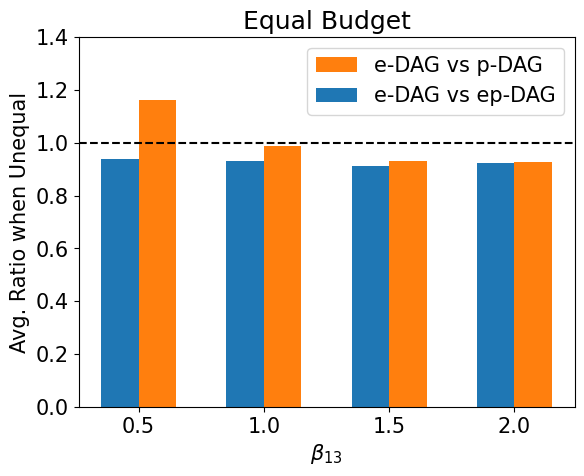

In [ ]:
plt.rcParams.update({'font.size': 15})
plt.bar(x=mu_1s, height = ratios_p, width = 0.15, align = 'edge', label = 'e-DAG vs p-DAG', color = 'C1')
plt.bar(x=mu_1s, height = ratios_ep, width = -0.15, align = 'edge', label = 'e-DAG vs ep-DAG', color = 'C0')

plt.ylim(0,1.4)
plt.xlabel(r'$\beta_{13}$')
plt.ylabel('Avg. Ratio when Unequal')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.title('Equal Budget')
plt.legend()
plt.show()

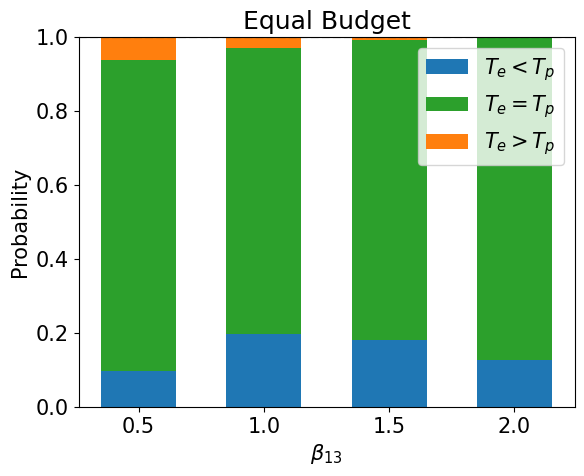

In [ ]:
plt.rcParams.update({'font.size': 15})
p_less_e = np.mean(np.minimum(Ts_array[:,:,0], 200) < np.minimum(Ts_array[:,:,1], 200), axis = 0)
e_less_p = np.mean(np.minimum(Ts_array[:,:,1], 200) < np.minimum(Ts_array[:,:,0], 200), axis = 0)
p_equal_e = np.mean(np.minimum(Ts_array[:,:,1], 200) == np.minimum(Ts_array[:,:,0], 200), axis = 0)
plt.bar(x=mu_1s, height = e_less_p, width = 0.3, align = 'center', label = r'$T_e<T_p$', color = 'C0')
plt.bar(x=mu_1s, height = p_equal_e, bottom = e_less_p, width = 0.3, align = 'center', label = r'$T_e=T_p$', color = 'C2')
plt.bar(x=mu_1s, height = p_less_e, bottom = e_less_p + p_equal_e, width = 0.3, align = 'center', label = r'$T_e>T_p$', color = 'C1')

plt.ylim(0, 1)
plt.xlabel(r'$\beta_{13}$')
plt.ylabel('Probability')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.title('Equal Budget')
plt.legend()
plt.show()

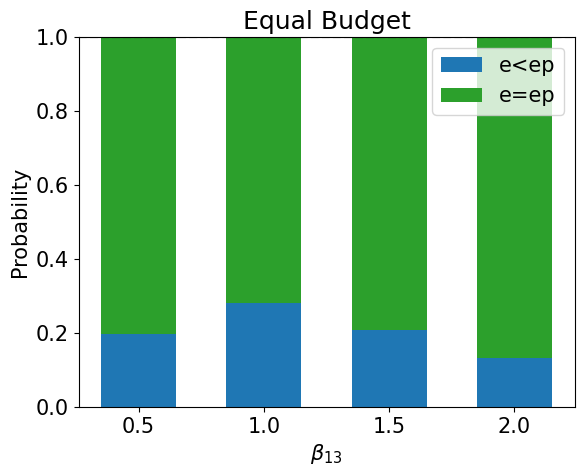

In [ ]:
plt.rcParams.update({'font.size': 15})
e_less_ep = np.mean(np.minimum(Ts_array[:,:,2], 200) > np.minimum(Ts_array[:,:,1], 200), axis = 0)
plt.bar(x=mu_1s, height = e_less_ep, width = 0.3, align = 'center', label = 'e<ep', color = 'C0')
plt.bar(x=mu_1s, height = 1 - e_less_ep, bottom = e_less_ep, width = 0.3, align = 'center', label = 'e=ep', color = 'C2')
plt.ylim(0, 1)
plt.xlabel(r'$\beta_{13}$')
plt.ylabel('Probability')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.title('Equal Budget')
plt.legend()
plt.show()

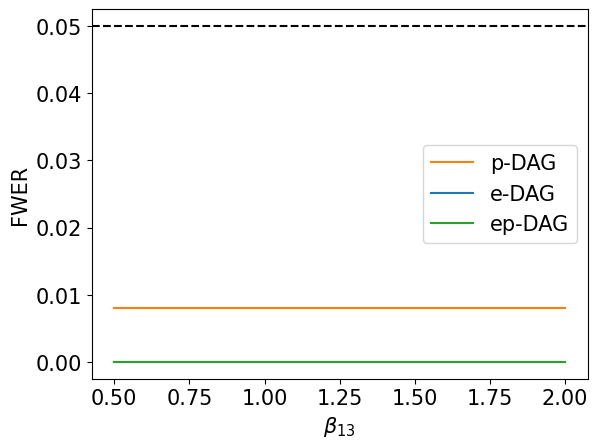

In [ ]:
plt.rcParams.update({'font.size': 15})
colors = ['C1', 'C0', 'C2']
methods = ['p-DAG','e-DAG','ep-DAG']
for i in range(3):
  plt.plot(mu_1s, np.mean(FWER_powers_array[:,:,i,0], axis = 0), label = methods[i], color = colors[i])

plt.xlabel(r'$\beta_{13}$')
plt.ylabel('FWER')
plt.axhline(0.05, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

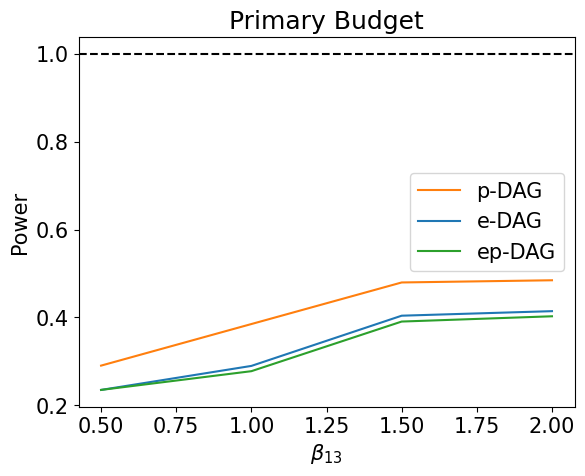

In [ ]:
plt.rcParams.update({'font.size': 15})
colors = ['C1', 'C0', 'C2']
methods = ['p-DAG','e-DAG','ep-DAG']
for i in range(3):
  plt.plot(mu_1s, np.mean(FWER_powers_array[:,:,i,1], axis = 0), label = methods[i], color = colors[i])

plt.xlabel(r'$\beta_{13}$')
plt.ylabel('Power')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.title('Primary Budget')
plt.legend()
plt.show()